# Unidad 7 · Clase 2 — Clasificación con k-NN

En la Clase 1 predijimos **cuánto vale** un diamante (regresión). Hoy usamos los mismos diamantes y la misma X, pero predecimos **a qué categoría de precio pertenece** (clasificación).

1. De regresión a clasificación
2. k-NN, accuracy y matriz de confusión
3. Validación cruzada y GridSearch
4. Escalado y Pipeline
5. Práctica de regresión: consumo de autos (`mpg`)
6. Práctica de clasificación: diagnóstico de tumores (`breast_cancer`)

# 0. Importar librerías

In [3]:
# Librerías para EDA
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [41]:
# Librerías para Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.datasets import load_wine, load_breast_cancer

# Métricas de clasificación
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
# Métricas de regresión (para la práctica 5)
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# 1. De regresión a clasificación

| | Clase 1 · Regresión | Hoy · Clasificación |
|---|---|---|
| Pregunta | ¿Cuánto vale? | ¿De qué categoría es? |
| X | quilates | quilates |
| y | precio (número) | categoria_precio (categoría) |
| Modelo | `KNeighborsRegressor` | `KNeighborsClassifier` |
| Métricas | RMSE, MAE, R² | Accuracy, matriz de confusión |

**La tarea la define el tipo de y**, no el algoritmo: k-NN sirve para las dos.

In [5]:
# Cargar dataset
df_raw = pd.read_csv("https://raw.githubusercontent.com/UADE-Python-Data-Science/583433_repo_oficial/refs/heads/main/Datasets/diamonds_clean.csv")
df_raw.shape


(53794, 13)

In [6]:
# Seleccionar columnas de interés y renombrarlas
df = df_raw[["carat", "price", "categoria_precio"]].rename(columns={
    "carat": "quilates",
    "price": "precio",
    "categoria_precio": "categoria"})

In [7]:
# Inspeccionamos la variable objetivo (variable a predecir)
df["categoria"].value_counts()

categoria
Medio        24658
Premiun      14691
Económico    14445
Name: count, dtype: int64

In [8]:
SEMILLA = 42
N_SAMPLE = 1000 # None para seleccionar todos los datos

En el CSV la categoría está escrita **"Premiun"** (con n). La corregimos para que las tablas y los gráficos queden bien.

In [9]:
df["categoria"] = df["categoria"].replace({"Premiun": "Premium","Económico": "Economico"})

# ¿Cómo se definió la categoría? Mínimo y máximo de precio en cada una
df.groupby("categoria")["precio"].agg(["min", "max", "count"])
# df.groupby("categoria")["precio"].describe()

,min,max,count
categoria,,,
Economico,326,999,14445
Medio,1000,4999,24658
Premium,5000,18823,14691


La categoría es el precio cortado en tres rangos: **menos de 1.000 USD**, **de 1.000 a 4.999** y **5.000 o más**.

> ⚠️ Por eso **el precio no puede ir en X**: la categoría se calcula a partir de él. Sería como darle al modelo la respuesta (fuga de datos).

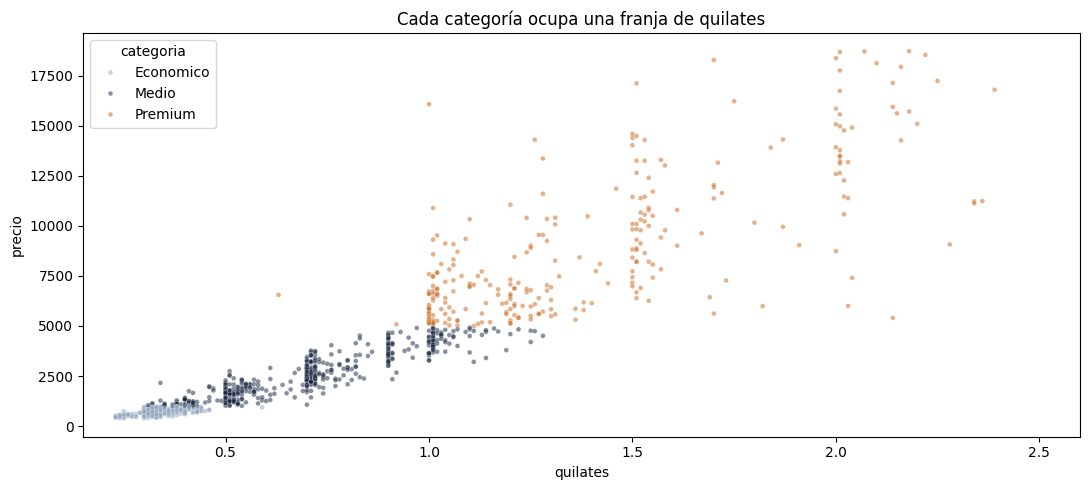

In [10]:
# EDA: precio vs quilates, coloreado por categoría (muestra de 6.000 diamantes)
muestra = df.sample(N_SAMPLE, random_state=SEMILLA)
orden = ["Economico", "Medio", "Premium"]

fig, ax = plt.subplots(figsize=(11, 5))
sns.scatterplot(data=muestra, x="quilates", y="precio", hue="categoria",
                hue_order=orden, palette=["#8FA3BF", "#14213D", "#C9661A"], s=12, alpha=0.5, ax=ax)
ax.set_xlim(0.15, 2.6)
ax.set_title("Cada categoría ocupa una franja de quilates")
plt.tight_layout()
plt.show()

In [11]:
# Proporción de cada categoría: las clases NO están balanceadas
df["categoria"].value_counts(normalize=True).loc[orden].round(3)

categoria
Economico    0.269
Medio        0.458
Premium      0.273
Name: proportion, dtype: float64

# 2. k-NN, accuracy y matriz de confusión

## 2.1 Separar train y test con `stratify`

En clasificación agregamos `stratify=y`: así train y test tienen **la misma proporción de cada categoría** que el dataset completo.

In [12]:
# Variables independientes o predictoras X
X = df[["quilates"]]

# Variable objetivo o variable respuesta y
y = df["categoria"]

# Split manual - elegimos un 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y) # Quitar stratify y ver que cambian

# Exploramos como quedo dividido el conjunto de train y test
print("Train:", X_train.shape, " Test:", X_test.shape)
pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).loc[orden].round(3)

Train: (43035, 1)  Test: (10759, 1)


,train,test
categoria,,
Economico,0.269,0.269
Medio,0.458,0.458
Premium,0.273,0.273


## 2.2 El baseline: predecir siempre la clase más frecuente

En regresión el baseline era predecir siempre la media. En clasificación es predecir siempre **la categoría más frecuente**. `DummyClassifier` hace exactamente eso.

In [13]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

acc_baseline = accuracy_score(y_test, baseline.predict(X_test))
print(f"Baseline (siempre '{baseline.predict(X_test)[0]}'): {acc_baseline:.1%}")

Baseline (siempre 'Medio'): 45.8%


## 2.3 k-NN clasificador: en vez de promediar, vota

Mismo flujo que en la Clase 1: crear, `fit`, `predict`. Lo único que cambia es la clase: `KNeighborsClassifier`. Para cada diamante busca los 5 más parecidos y devuelve **la categoría más votada**.

In [14]:
# Crear el modelo
knn = KNeighborsClassifier(n_neighbors=5)

# Entrenamos el modelo a partir de los datos de training
knn.fit(X_train, y_train)

# Usamos el modelo resultante para predecir las clases (en regresión eran precios) a partir de los quilates del conjunto de testing (X_test)
y_pred = knn.predict(X_test)

y_pred[:10]

array(['Medio', 'Medio', 'Premium', 'Medio', 'Economico', 'Economico',
       'Economico', 'Medio', 'Premium', 'Premium'], dtype=object)

In [15]:
# Un diamante de test y sus 5 vecinos: ¿cómo votaron?
i = 0
diamante = X_test.iloc[[i]]
distancias, posiciones = knn.kneighbors(diamante)

vecinos = X_train.iloc[posiciones[0]].copy()
vecinos["categoria"] = y_train.iloc[posiciones[0]].values
print(f"Diamante de {diamante['quilates'].iloc[0]} quilates · real: {y_test.iloc[i]} · predicción: {y_pred[i]}")
vecinos

Diamante de 0.53 quilates · real: Medio · predicción: Medio


,quilates,categoria
44781,0.53,Medio
42031,0.53,Medio
44469,0.53,Medio
47126,0.53,Medio
46552,0.53,Medio


## 2.4 Accuracy: el porcentaje de aciertos

In [45]:
acc_knn = accuracy_score(y_test, y_pred)

print("Accuracy/Exactitud:")
print(f"Baseline: {acc_baseline:.1%}")
print(f"k-NN k=5: {acc_knn:.1%}")
print(f"\nAciertos: {(y_test == y_pred).sum():,} de {len(y_test):,}")

Accuracy/Exactitud:
Baseline: 45.8%
k-NN k=5: 83.4%

Aciertos: 8,973 de 10,759


## 2.5 Matríz de confusión

In [38]:
# Calcular la matríz de confusión
cm = confusion_matrix(y_test, y_pred, labels=orden)
pd.DataFrame(cm, index=[f"real {c}" for c in orden], columns=[f"pred {c}" for c in orden])

,pred Economico,pred Medio,pred Premium
real Economico,2323,566,0
real Medio,239,4022,671
real Premium,0,310,2628


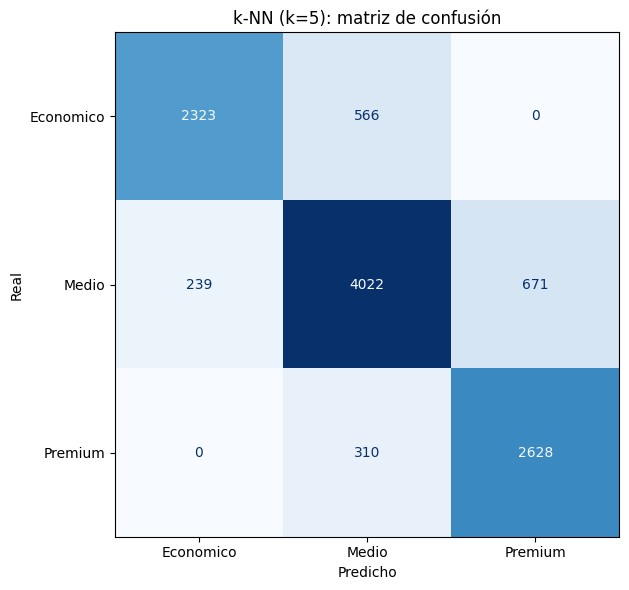

In [46]:
# Graficamos la matríz de confusión
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=orden).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("k-NN (k=5): matriz de confusión")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

**Cómo leerla:**

- **Nunca confunde los extremos**: ningún Económico se predice como Premium, ni al revés. Los errores son siempre con la categoría vecina.
- **El error más común** es predecir Premium para un diamante Medio. ¿Qué diamantes son?

In [19]:
# Los diamantes Medios que el modelo predijo como Premium
error = (y_test == "Medio") & (y_pred == "Premium")
print("Cantidad:", error.sum())
X_test[error]["quilates"].describe().round(2)

Cantidad: 671


count    671.00
mean       1.09
std        0.09
min        1.01
25%        1.01
50%        1.06
75%        1.14
max        1.52
Name: quilates, dtype: float64

Son todos diamantes de **1,01 quilates o más** que cuestan menos de 5.000 USD. Con solo los quilates, el modelo no tiene forma de saber que son baratos para su tamaño (el corte, el color o la claridad lo explicarían).

## 2.6 Analizamos las métricas

In [42]:
print(classification_report(y_test, y_pred, labels=orden, digits=3))

              precision    recall  f1-score   support

   Economico      0.907     0.804     0.852      2889
       Medio      0.821     0.815     0.818      4932
     Premium      0.797     0.894     0.843      2938

    accuracy                          0.834     10759
   macro avg      0.841     0.838     0.838     10759
weighted avg      0.837     0.834     0.834     10759



`accuracy`: aciertos / total de casos

`precision`: de los que el modelo predijo en esa clase, ¿cuántos eran de verdad? TP / (TP + FP) Mirar verticalmente

`recall`: de los que eran de esa clase, ¿cuántos encontró? TP / (TP + FN) Mirar horizontalmente

`f1-score`: el promedio armónico de precision y recall. Resume las dos en un número y baja si alguna de las dos es mala.

`support`: cuántos casos reales hay de esa clase en test.

`macro avg`: el promedio simple de las clases; todas pesan igual.

`weighted avg`: el promedio ponderado por support; las clases grandes pesan más.

### Conclusión: accuracy y F1 en los diamantes

**Las dos métricas cuentan casi la misma historia.** El accuracy (0,838) y el F1 macro (0,843) dan prácticamente lo mismo. Pasa porque las clases están razonablemente balanceadas (27% · 46% · 27%) y porque ningún error es más grave que otro: confundir un Medio con un Premium cuesta lo mismo que confundir un Económico con un Medio. En un problema así, el accuracy alcanza para comparar modelos, y es la más fácil de explicar.

**Donde se separan es frente al baseline.** Un modelo que predice siempre «Medio» tiene 45,8% de accuracy, que no parece tan malo. Su F1 macro, en cambio, es de apenas 0,21: el F1 de Económico y de Premium es 0, porque nunca los predice. El F1 macro castiga a un modelo que ignora clases; el accuracy no.

**El F1 por clase muestra dónde le cuesta al modelo:**

- **Económico** tiene el F1 más alto (0,871): es la clase más fácil, porque los diamantes chicos casi siempre son baratos.
- **Medio** tiene el más bajo (0,821): es la clase del medio y se confunde para los dos lados. Se le escapan 307 hacia Económico y 643 hacia Premium.
- **Premium** tiene recall alto (0,876) pero precision más baja (0,800). El modelo encuentra casi todos los Premium, pero a cambio marca como Premium a 643 diamantes Medios de entre 1,01 y 1,52 quilates.

**Para mejorar no alcanza con cambiar k:** el error está en los diamantes del mismo tamaño con precios distintos. Hacen falta más variables, como el corte, el color o la claridad.

# 3. Validación cruzada y GridSearch

Igual que en la Clase 1: **k no se elige mirando el test**. Usamos validación cruzada dentro de train.

En clasificación se usa `StratifiedKFold`: cada una de las 5 partes mantiene la proporción de categorías. Y, como el CSV no viene en orden aleatorio, `shuffle=True`.

In [20]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_train, y_train,
                         cv=kfold, scoring="accuracy")

print("Accuracy de cada ronda:", scores.round(3))
print(f"Promedio: {scores.mean():.1%} ± {scores.std():.1%}")

Accuracy de cada ronda: [0.842 0.84  0.83  0.833 0.839]
Promedio: 83.7% ± 0.5%


En clasificación el scoring es `"accuracy"` y **no lleva signo negativo**: más alto ya es mejor.

In [21]:
grilla = {"n_neighbors": [1, 5, 15, 50, 100, 200, 400]}

busqueda = GridSearchCV(KNeighborsClassifier(), grilla, cv=kfold, scoring="accuracy")
busqueda.fit(X_train, y_train)   # 7 valores x 5 rondas = 35 modelos

print("Mejor k:", busqueda.best_params_)
print(f"Accuracy de validación: {busqueda.best_score_:.1%}")

Mejor k: {'n_neighbors': 400}
Accuracy de validación: 85.2%


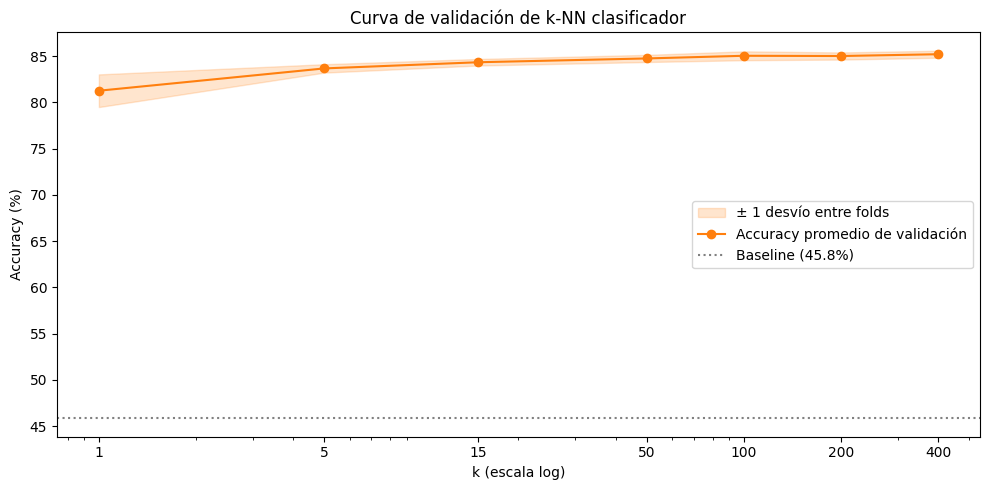

In [22]:
# Curva de validación
res = pd.DataFrame(busqueda.cv_results_)
k_vals = res["param_n_neighbors"].astype(int)
media = res["mean_test_score"] * 100
desvio = res["std_test_score"] * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(k_vals, media - desvio, media + desvio, color="tab:orange", alpha=0.2, label="± 1 desvío entre folds")
ax.plot(k_vals, media, marker="o", color="tab:orange", label="Accuracy promedio de validación")
ax.axhline(acc_baseline * 100, color="gray", linestyle=":", label=f"Baseline ({acc_baseline:.1%})")
ax.set_xscale("log")
ax.set_xticks(k_vals)
ax.set_xticklabels(k_vals)
ax.set_xlabel("k (escala log)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Curva de validación de k-NN clasificador")
ax.legend()
plt.tight_layout()
plt.show()

- Con **k = 1** el accuracy es el más bajo y el más variable entre rondas (sobreajuste).
- **Desde k = 50 la curva casi no sube**: menos de medio punto. Ante un empate práctico, se puede elegir un k más chico y rápido.

Ahora sí, **una sola vez**, el test:

Accuracy en test (k=400): 85.2%


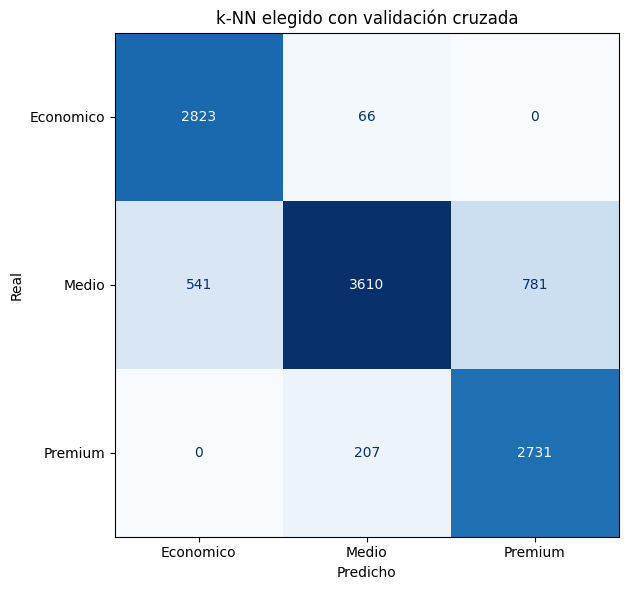

In [23]:
mejor_knn = busqueda.best_estimator_      # ya reentrenado con todo train
y_pred_cv = mejor_knn.predict(X_test)

print(f"Accuracy en test (k={busqueda.best_params_['n_neighbors']}): {accuracy_score(y_test, y_pred_cv):.1%}")

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_cv, labels=orden, ax=ax, cmap="Blues", colorbar=False)
ax.set_title("k-NN elegido con validación cruzada")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

# 4. Escalado y Pipeline

Con los diamantes había **una sola columna** en X, así que escalar no cambiaba nada. Para ver por qué importa, usamos un dataset con **muchas columnas en escalas muy distintas**: los vinos de scikit-learn (178 vinos, 13 variables químicas, 3 variedades).

In [24]:
vinos = load_wine(as_frame=True)
X_v = vinos.data
y_v = vinos.target

# Rango de cada columna: algunas van de 0 a 1, otra de 278 a 1.680
X_v.describe().loc[["min", "max"]].T.sort_values("max")

,min,max
nonflavanoid_phenols,0.13,0.66
hue,0.48,1.71
ash,1.36,3.23
proanthocyanins,0.41,3.58
total_phenols,0.98,3.88
od280/od315_of_diluted_wines,1.27,4.00
flavanoids,0.34,5.08
malic_acid,0.74,5.80
color_intensity,1.28,13.00
alcohol,11.03,14.83


In [25]:
Xv_train, Xv_test, yv_train, yv_test = train_test_split(
    X_v, y_v, test_size=0.2, random_state=42, stratify=y_v)

# k-NN sin escalar
knn_crudo = KNeighborsClassifier(n_neighbors=5).fit(Xv_train, yv_train)
print(f"k-NN sin escalar: {accuracy_score(yv_test, knn_crudo.predict(Xv_test)):.1%}")

k-NN sin escalar: 80.6%


**El problema:** k-NN mide distancias. `proline` (de 278 a 1.680) domina la distancia y las otras 12 columnas casi no cuentan.

**La solución:** `StandardScaler` lleva cada columna a media 0 y desvío 1. Y para no olvidarnos de escalar test con la media de train, lo encadenamos con el modelo en un **Pipeline**:

- `pipe.fit(X_train, y_train)` → el scaler calcula media y desvío **solo con train**, transforma y entrena.
- `pipe.predict(X_test)` → transforma test **con esa misma** media y desvío, y predice.

In [26]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])
pipe.fit(Xv_train, yv_train)
print(f"k-NN escalado: {accuracy_score(yv_test, pipe.predict(Xv_test)):.1%}")

k-NN escalado: 97.2%


## 4.1 GridSearch sobre el Pipeline

Para nombrar un hiperparámetro de un paso del Pipeline: `nombre_del_paso__parametro` (dos guiones bajos). Dentro de la validación cruzada, el scaler se reajusta en cada ronda solo con la parte de entrenamiento: no hay filtraciones.

In [27]:
pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
grilla_pipe = {"knn__n_neighbors": [1, 3, 5, 7, 9, 15, 25]}

busqueda_v = GridSearchCV(pipe, grilla_pipe, cv=kfold, scoring="accuracy")
busqueda_v.fit(Xv_train, yv_train)

print("Mejor:", busqueda_v.best_params_)
print(f"Accuracy de validación: {busqueda_v.best_score_:.1%}")
print(f"Accuracy en test:       {accuracy_score(yv_test, busqueda_v.predict(Xv_test)):.1%}  ({len(yv_test)} vinos)")

Mejor: {'knn__n_neighbors': 25}
Accuracy de validación: 96.5%
Accuracy en test:       100.0%  (36 vinos)


> Con solo 36 vinos en test, **cada vino mueve el accuracy casi 3 puntos**. El accuracy de validación cruzada es una estimación más estable que el del test.

## 4.2 Comparación final

In [28]:
pd.DataFrame({
    "modelo": ["Baseline (clase más frecuente)", "k-NN k=5 sin escalar", "k-NN k=5 escalado (Pipeline)", "Mejor k-NN (GridSearch + Pipeline)"],
    "diamantes": [acc_baseline, acc_knn, acc_knn, accuracy_score(y_test, y_pred_cv)],
    "vinos": [yv_test.value_counts(normalize=True).max(),
              accuracy_score(yv_test, knn_crudo.predict(Xv_test)),
              accuracy_score(yv_test, Pipeline([("s", StandardScaler()), ("k", KNeighborsClassifier(5))]).fit(Xv_train, yv_train).predict(Xv_test)),
              accuracy_score(yv_test, busqueda_v.predict(Xv_test))],
}).set_index("modelo").map(lambda v: f"{v:.1%}")

,diamantes,vinos
modelo,,
Baseline (clase más frecuente),45.8%,38.9%
k-NN k=5 sin escalar,83.4%,80.6%
k-NN k=5 escalado (Pipeline),83.4%,97.2%
Mejor k-NN (GridSearch + Pipeline),85.2%,100.0%


- **Diamantes**: con una sola columna, escalar no cambia nada (por eso la fila 2 y la 3 son iguales). El techo de ~85% lo pone la falta de variables, no el algoritmo.
- **Vinos**: escalar cambia todo. Con 13 columnas en escalas distintas, k-NN necesita el Pipeline.

# 5. Práctica de regresión: consumo de autos

Dataset `mpg` de seaborn: 398 autos de los años 70 y 80. Queremos predecir el **consumo en millas por galón** (`mpg`: más millas, menos consumo) a partir del peso, la potencia y la aceleración.

**Consignas**

1. Cargá el dataset y revisá la **calidad**: ¿hay nulos? ¿en qué columna?
2. Explorá la relación de `mpg` con `weight`, `horsepower` y `acceleration` (scatterplots y correlación).
3. Separá 80/20 con `random_state=42`.
4. Entrená una **regresión lineal** y un **k-NN** (k=5). Calculá RMSE y R², y compará con el baseline (predecir la media).
5. Probá k-NN **con Pipeline y escalado**, y elegí k con `GridSearchCV`. ¿Mejora? ¿Por qué?

---
### Solución

In [29]:
mpg = sns.load_dataset("mpg")
print(mpg.shape)
mpg.isna().sum()

(398, 9)


mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

In [30]:
# 6 autos sin potencia: los sacamos (scikit-learn no acepta nulos)
mpg = mpg.dropna(subset=["horsepower"])
print(mpg.shape)

(392, 9)


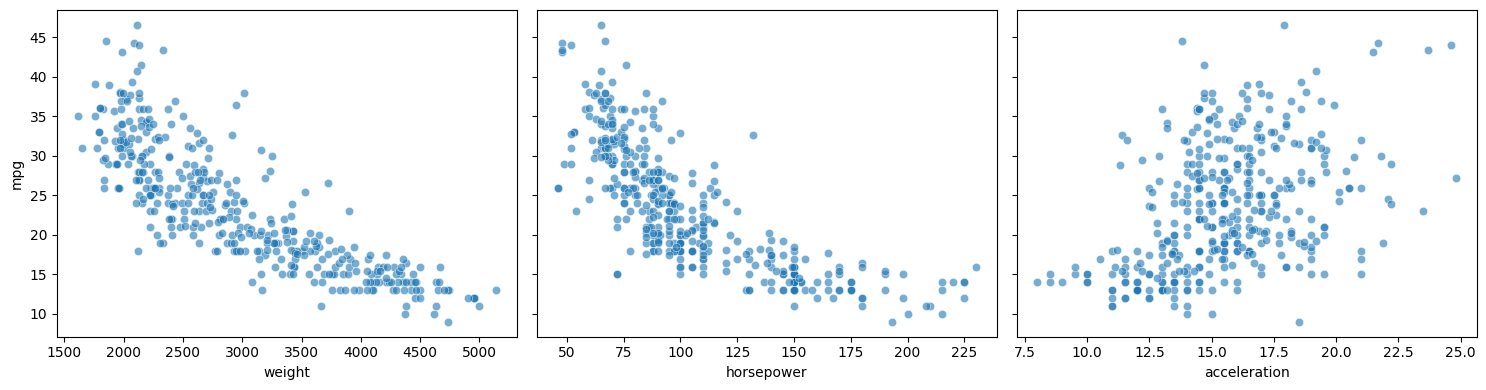

weight         -0.83
horsepower     -0.78
acceleration    0.42
mpg             1.00
Name: mpg, dtype: float64

In [31]:
variables = ["weight", "horsepower", "acceleration"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, variables):
    sns.scatterplot(data=mpg, x=col, y="mpg", ax=ax, alpha=0.6)
plt.tight_layout()
plt.show()

mpg[variables + ["mpg"]].corr()["mpg"].round(2)

In [32]:
Xm = mpg[variables]
ym = mpg["mpg"]
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.2, random_state=42)

def evaluar_reg(nombre, y_real, y_pred):
    return {"modelo": nombre,
            "RMSE": root_mean_squared_error(y_real, y_pred),
            "MAE": mean_absolute_error(y_real, y_pred),
            "R²": r2_score(y_real, y_pred)}

rl = LinearRegression().fit(Xm_train, ym_train)
knn_m = KNeighborsRegressor(n_neighbors=5).fit(Xm_train, ym_train)

resultados_mpg = [
    evaluar_reg("Media (baseline)", ym_test, np.full(len(ym_test), ym_train.mean())),
    evaluar_reg("Regresión lineal", ym_test, rl.predict(Xm_test)),
    evaluar_reg("k-NN k=5 sin escalar", ym_test, knn_m.predict(Xm_test)),
]
pd.DataFrame(resultados_mpg).round(2)

,modelo,RMSE,MAE,R²
0,Media (baseline),7.18,5.88,-0.01
1,Regresión lineal,4.22,3.51,0.65
2,k-NN k=5 sin escalar,4.03,2.98,0.68


In [33]:
pipe_m = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor())])
busqueda_m = GridSearchCV(pipe_m, {"knn__n_neighbors": [1, 3, 5, 7, 10, 15, 20, 30, 50]},
                          cv=KFold(n_splits=5, shuffle=True, random_state=42),
                          scoring="neg_root_mean_squared_error")
busqueda_m.fit(Xm_train, ym_train)
print("Mejor:", busqueda_m.best_params_)

resultados_mpg.append(evaluar_reg(f"k-NN escalado (k={busqueda_m.best_params_['knn__n_neighbors']})", ym_test, busqueda_m.predict(Xm_test)))
pd.DataFrame(resultados_mpg).round(2)

Mejor: {'knn__n_neighbors': 30}


,modelo,RMSE,MAE,R²
0,Media (baseline),7.18,5.88,-0.01
1,Regresión lineal,4.22,3.51,0.65
2,k-NN k=5 sin escalar,4.03,2.98,0.68
3,k-NN escalado (k=30),4.15,3.09,0.66


**Para discutir:** acá escalar **no mejora**. Sin escalar, `weight` (de 1.600 a 5.100 libras) domina la distancia... pero `weight` es justamente la variable más relacionada con el consumo (correlación −0,83). La escala "eligió" bien por casualidad. Con 79 autos de test, las diferencias entre modelos son chicas y ruidosas.

# 6. Práctica de clasificación: diagnóstico de tumores

Dataset `load_breast_cancer` de scikit-learn: 569 tumores con 30 medidas de las células. Queremos predecir si el tumor es **maligno o benigno**.

**Consignas**

1. Cargá el dataset con `as_frame=True`. ¿Cuántos casos de cada clase hay? Ojo: **0 = maligno, 1 = benigno**.
2. Separá 80/20 con `random_state=42` y `stratify=y`.
3. Entrená k-NN (k=5) sin escalar: accuracy y matriz de confusión.
4. Repetí con Pipeline y escalado. Elegí k con `GridSearchCV`.
5. En la matriz de confusión, ¿cuántos tumores **malignos** se predijeron como **benignos**? ¿Por qué ese error es más grave que el contrario?

---
### Solución

In [34]:
tumores = load_breast_cancer(as_frame=True)
X_t = tumores.data
y_t = tumores.target
print(X_t.shape)
y_t.map({0: "maligno", 1: "benigno"}).value_counts()

(569, 30)


target
benigno    357
maligno    212
Name: count, dtype: int64

In [35]:
# Escalas muy distintas: de milésimas a miles
X_t.describe().loc[["min", "max"]].T.sort_values("max").iloc[[0, 1, -2, -1]]

,min,max
fractal dimension error,0.000895,0.02984
smoothness error,0.001713,0.03113
mean area,143.500000,2501.00000
worst area,185.200000,4254.00000


In [36]:
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    X_t, y_t, test_size=0.2, random_state=42, stratify=y_t)

nombres = ["maligno", "benigno"]   # 0 y 1

knn_t = KNeighborsClassifier(n_neighbors=5).fit(Xt_train, yt_train)
print(f"Baseline:          {yt_test.value_counts(normalize=True).max():.1%}")
print(f"k-NN sin escalar:  {accuracy_score(yt_test, knn_t.predict(Xt_test)):.1%}")

busqueda_t = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())]),
    {"knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31]},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), scoring="accuracy")
busqueda_t.fit(Xt_train, yt_train)
print(f"k-NN escalado (k={busqueda_t.best_params_['knn__n_neighbors']}): {accuracy_score(yt_test, busqueda_t.predict(Xt_test)):.1%}")

Baseline:          63.2%
k-NN sin escalar:  91.2%
k-NN escalado (k=9): 97.4%


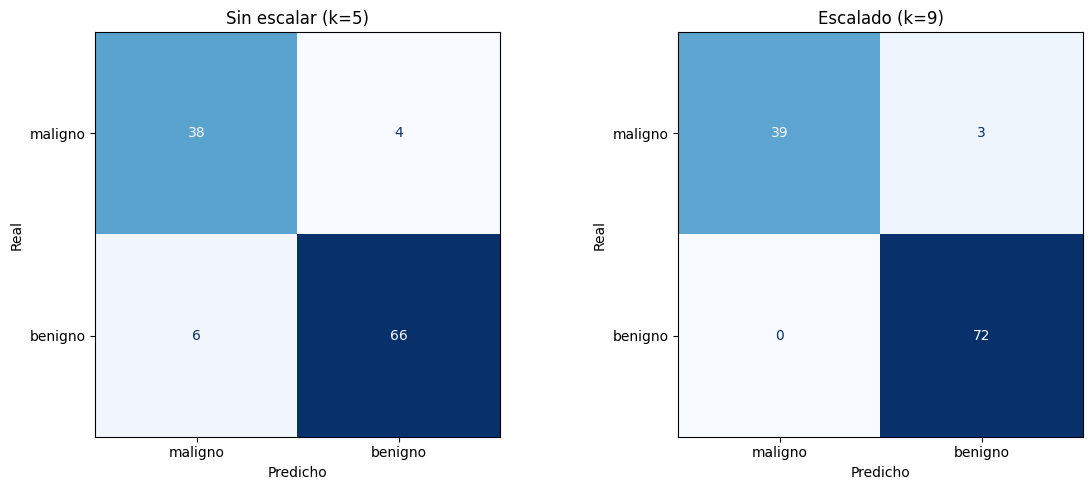

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(yt_test, knn_t.predict(Xt_test), display_labels=nombres,
                                        ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Sin escalar (k=5)")
ConfusionMatrixDisplay.from_predictions(yt_test, busqueda_t.predict(Xt_test), display_labels=nombres,
                                        ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title(f"Escalado (k={busqueda_t.best_params_['knn__n_neighbors']})")
for ax in axes:
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

**Para discutir:** la celda *real maligno → predicho benigno* es un **falso negativo**: un tumor maligno que el modelo deja pasar. En un diagnóstico es mucho más grave que el error contrario (un benigno que se manda a estudiar de más). Por eso, en estos problemas, el accuracy solo no alcanza: hay que mirar **en qué** se equivoca el modelo.